In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import SMOTENC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
columns = df.columns
print(columns)

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')


In [4]:
for column in columns[:10]:
    print(f"column name: {column} {df[column].unique()}")
    print(f"Length: {len(df[column].unique())}")

column name: customerID ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
Length: 7043
column name: gender ['Female' 'Male']
Length: 2
column name: SeniorCitizen [0 1]
Length: 2
column name: Partner ['Yes' 'No']
Length: 2
column name: Dependents ['No' 'Yes']
Length: 2
column name: tenure [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
Length: 73
column name: PhoneService ['No' 'Yes']
Length: 2
column name: MultipleLines ['No phone service' 'No' 'Yes']
Length: 3
column name: InternetService ['DSL' 'Fiber optic' 'No']
Length: 3
column name: OnlineSecurity ['No' 'Yes' 'No internet service']
Length: 3


In [5]:
for column in columns[10:]:
    print(f"column name: {column} {df[column].unique()}")
    print(f"Length: {len(df[column].unique())}")

column name: OnlineBackup ['Yes' 'No' 'No internet service']
Length: 3
column name: DeviceProtection ['No' 'Yes' 'No internet service']
Length: 3
column name: TechSupport ['No' 'Yes' 'No internet service']
Length: 3
column name: StreamingTV ['No' 'Yes' 'No internet service']
Length: 3
column name: StreamingMovies ['No' 'Yes' 'No internet service']
Length: 3
column name: Contract ['Month-to-month' 'One year' 'Two year']
Length: 3
column name: PaperlessBilling ['Yes' 'No']
Length: 2
column name: PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Length: 4
column name: MonthlyCharges [29.85 56.95 53.85 ... 63.1  44.2  78.7 ]
Length: 1585
column name: TotalCharges ['29.85' '1889.5' '108.15' ... '346.45' '306.6' '6844.5']
Length: 6531
column name: Churn ['No' 'Yes']
Length: 2


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:
print(f"Duplicated Data: {df.duplicated().sum()}")

Duplicated Data: 0


In [10]:
df = df.drop(columns=["customerID"])

In [11]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [12]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")

In [13]:
print(f"Null Value in TotalCharges: {df['TotalCharges'].isnull().sum()}")

Null Value in TotalCharges: 11


In [14]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [15]:
print(f"Null Value in TotalCharges: {df['TotalCharges'].isnull().sum()}")

Null Value in TotalCharges: 0


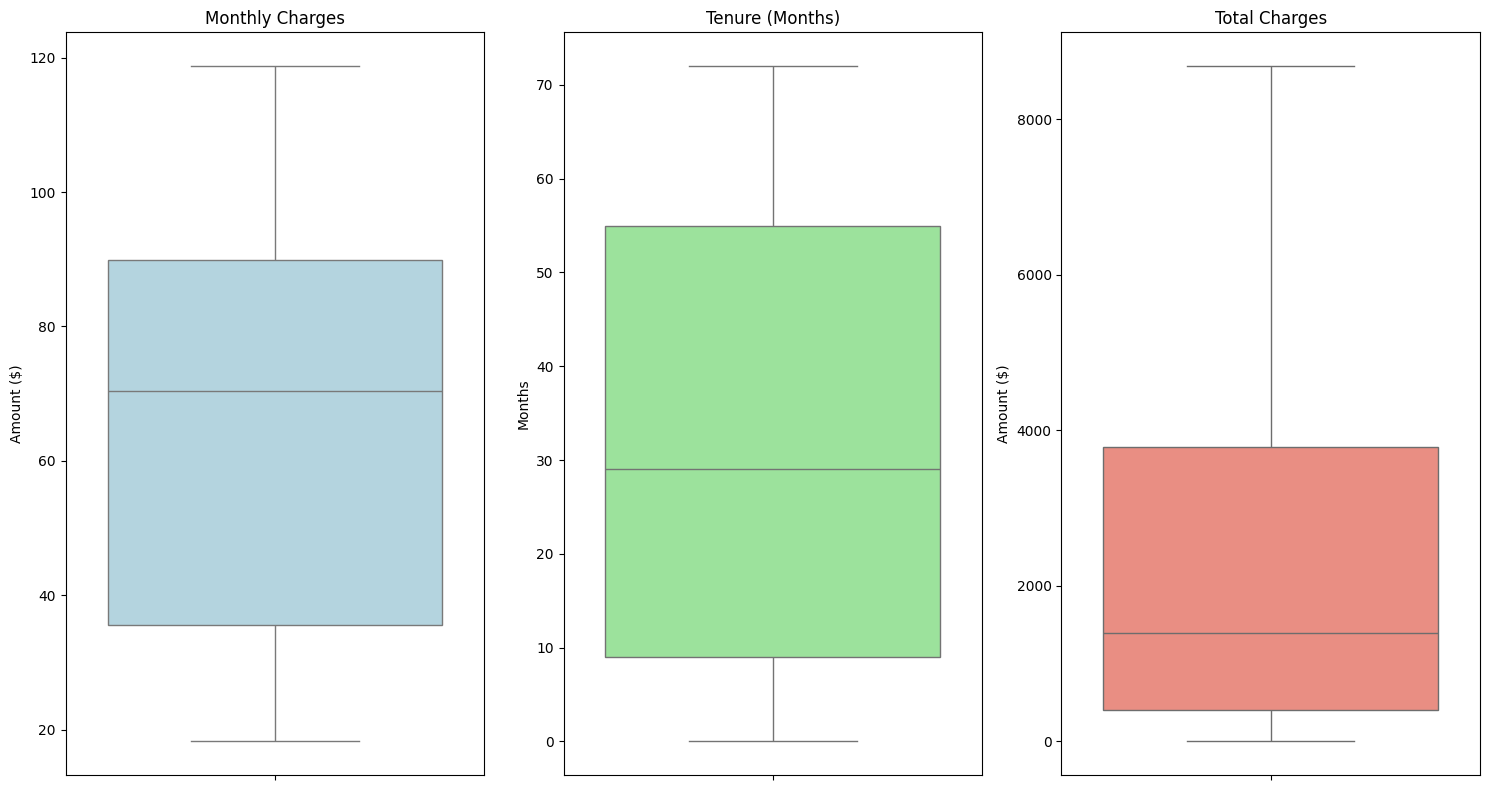

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 8))

sns.boxplot(y=df["MonthlyCharges"], ax=axes[0] , color='lightblue')
axes[0].set_title('Monthly Charges')
axes[0].set_ylabel('Amount ($)')

sns.boxplot(y=df['tenure'], ax=axes[1], color='lightgreen')
axes[1].set_title('Tenure (Months)')
axes[1].set_ylabel('Months')

sns.boxplot(y=df['TotalCharges'], ax=axes[2], color='salmon')
axes[2].set_title('Total Charges')
axes[2].set_ylabel('Amount ($)')

plt.tight_layout()

plt.show()

In [17]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

C:\Users\new\AppData\Local\Temp\ipykernel_9460\3651206362.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df , x="Churn" , palette="Set2")


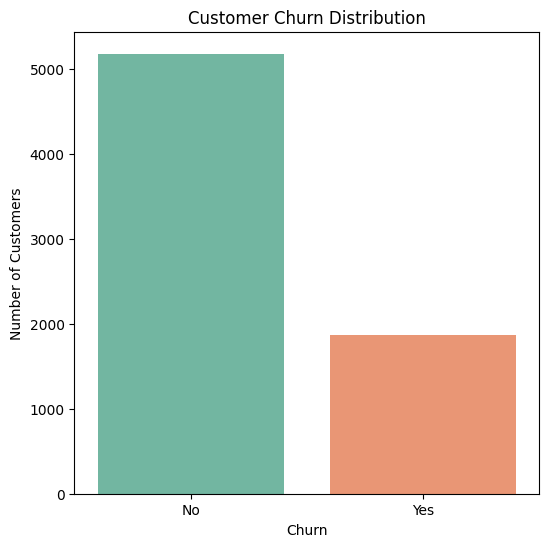

In [18]:
plt.figure(figsize=(6, 6))
sns.countplot(data=df , x="Churn" , palette="Set2")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

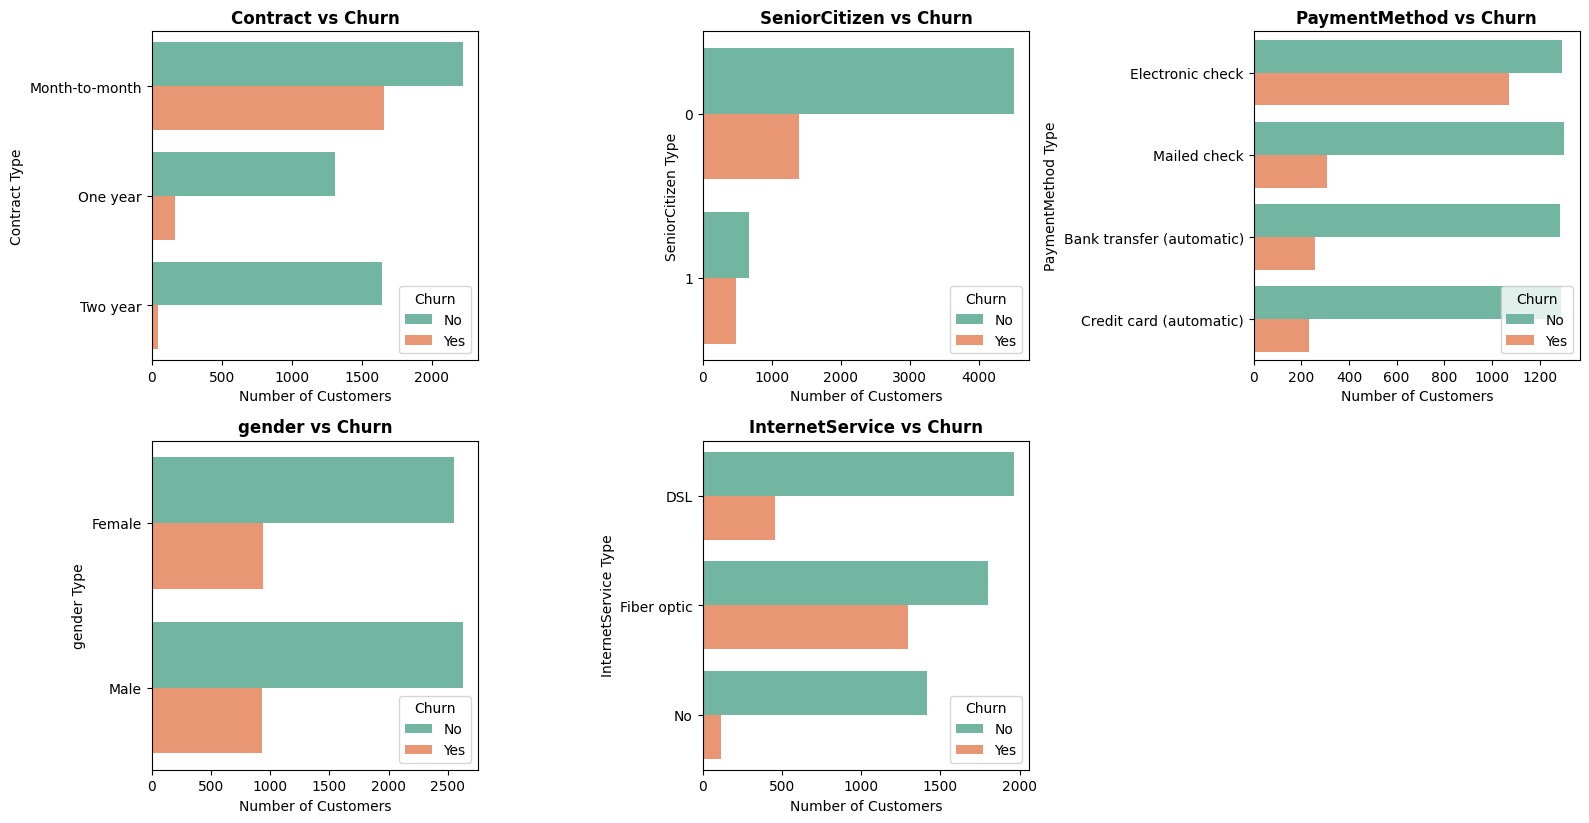

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))


columns = ["Contract" , "SeniorCitizen" , "PaymentMethod" , "gender" ,"InternetService"]

axes_flat = axes.flatten()

for i , col in enumerate(columns):
    sns.countplot(
        data=df, 
        y=df[col],
        hue="Churn", 
        ax=axes_flat[i],   
        palette="Set2"  
    )

    axes_flat[i].set_title(f'{col} vs Churn', fontsize=12, fontweight='bold')
    axes_flat[i].set_xlabel('Number of Customers')
    axes_flat[i].set_ylabel(f'{col} Type')
    
for j in range(len(columns), len(axes_flat)):
    fig.delaxes(axes_flat[j])
    
plt.tight_layout()
plt.show()

C:\Users\new\AppData\Local\Temp\ipykernel_9460\2756623707.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='tenure', palette='Set2')


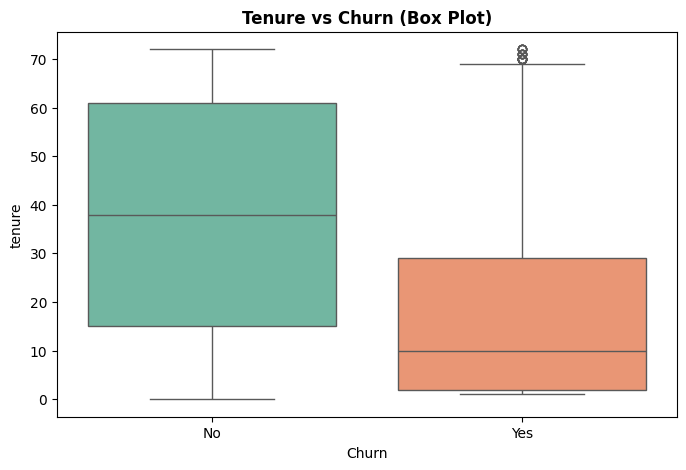

In [20]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Churn', y='tenure', palette='Set2')
plt.title('Tenure vs Churn (Box Plot)', fontsize=12, fontweight='bold')
plt.show()

C:\Users\new\AppData\Local\Temp\ipykernel_9460\4224093222.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette='Set2')


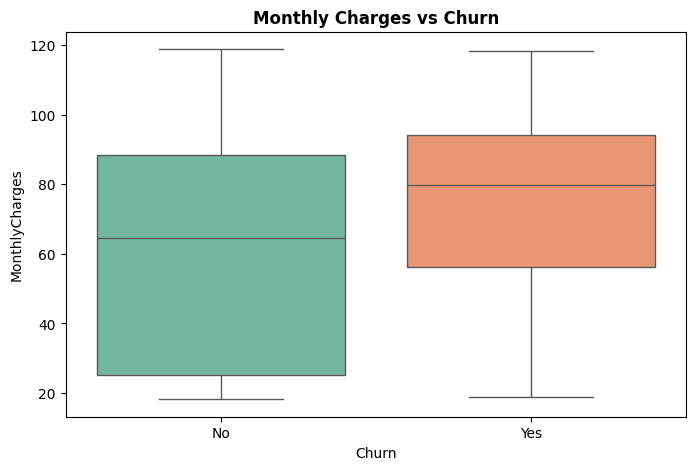

In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette='Set2')
plt.title('Monthly Charges vs Churn', fontsize=12, fontweight='bold')
plt.show()

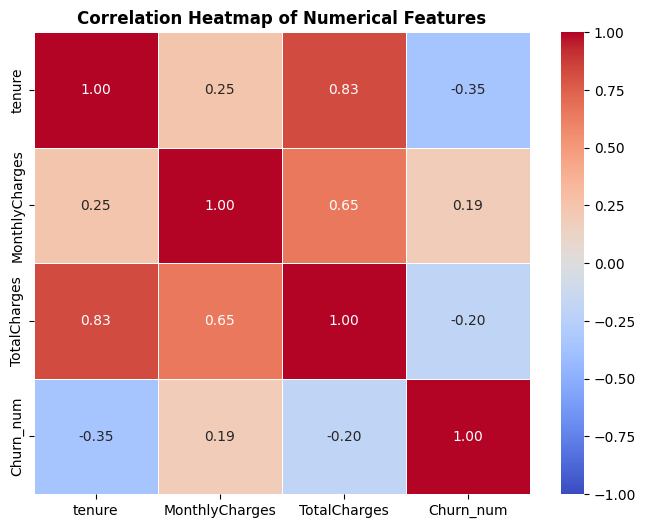

In [22]:
df['Churn_num'] = df['Churn'].map({'Yes': 1, 'No': 0})

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_num']

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, 
    annot=True,         
    cmap='coolwarm',    
    fmt=".2f",           
    linewidths=0.5,     
    vmin=-1, vmax=1 
)

plt.title('Correlation Heatmap of Numerical Features', fontsize=12, fontweight='bold')
plt.show()

In [23]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_num
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [24]:
df = df.drop(columns="Churn_num")

In [25]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [26]:
df["Churn"] = df["Churn"].map({"Yes" : 1 , "No" : 0})

In [27]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train , X_temp , y_train , y_temp = train_test_split(X , y , test_size=0.3, random_state=42 , stratify=y )

X_test, X_val , y_test , y_val = train_test_split(X_temp , y_temp , test_size=0.5, random_state=42 , stratify=y_temp )

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (4930, 19)
Validation set: (1057, 19)
Test set: (1056, 19)


In [29]:

for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name} set:")
    print(target.value_counts())
    print("Churn rate:", round(target.mean(), 4))



Train set:
Churn
0    3622
1    1308
Name: count, dtype: int64
Churn rate: 0.2653

Validation set:
Churn
0    776
1    281
Name: count, dtype: int64
Churn rate: 0.2658

Test set:
Churn
0    776
1    280
Name: count, dtype: int64
Churn rate: 0.2652


In [30]:
print(f"X Train Shape : {X_train.shape}")
print(f"X Test Shape : {X_test.shape}")
print(f"y Train Shape : {y_train.shape}")
print(f"y Test Shape : {y_test.shape}")

X Train Shape : (4930, 19)
X Test Shape : (1056, 19)
y Train Shape : (4930,)
y Test Shape : (1056,)


In [31]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal features:", len(numerical_features) + len(categorical_features))

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total features: 19


In [32]:

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [33]:
logistic_model = Pipeline(
    steps = [
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

In [34]:
logistic_model.fit(X_train , y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [35]:
y_val_pred = logistic_model.predict(X_val)
y_val_proba = logistic_model.predict_proba(X_val)[:, 1]

print("Logistic Regression - Baseline")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, y_val_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_proba), 4))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_val, y_val_pred)
print(cm)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

Logistic Regression - Baseline
----------------------------------------
Accuracy: 0.8117
Precision: 0.6916
Recall: 0.5267
F1-score: 0.598
ROC-AUC: 0.8448

Confusion Matrix:
[[710  66]
 [133 148]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.88       776
           1       0.69      0.53      0.60       281

    accuracy                           0.81      1057
   macro avg       0.77      0.72      0.74      1057
weighted avg       0.80      0.81      0.80      1057



In [36]:
for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_val_pred_threshold = (
        y_val_proba >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")
    print(
        "Precision:",
        round(precision_score(y_val, y_val_pred_threshold), 4)
    )
    print(
        "Recall:",
        round(recall_score(y_val, y_val_pred_threshold), 4)
    )
    print(
        "F1-score:",
        round(f1_score(y_val, y_val_pred_threshold), 4)
    )


Threshold: 0.3
Precision: 0.5443
Recall: 0.7438
F1-score: 0.6286

Threshold: 0.4
Precision: 0.5929
Recall: 0.6584
F1-score: 0.6239

Threshold: 0.5
Precision: 0.6916
Recall: 0.5267
F1-score: 0.598

Threshold: 0.6
Precision: 0.7293
Recall: 0.3452
F1-score: 0.4686


In [38]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [39]:
rf_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [40]:
y_val_pred_rf = rf_model.predict(X_val)
y_val_proba_rf = rf_model.predict_proba(X_val)[:, 1]

print("Random Forest - Baseline")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_val, y_val_pred_rf), 4))
print("Precision:", round(precision_score(y_val, y_val_pred_rf), 4))
print("Recall:", round(recall_score(y_val, y_val_pred_rf), 4))
print("F1-score:", round(f1_score(y_val, y_val_pred_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_proba_rf), 4))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_val, y_val_pred_rf)
print(cm)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf, zero_division=0))

Random Forest - Baseline
----------------------------------------
Accuracy: 0.7862
Precision: 0.6341
Recall: 0.4626
F1-score: 0.535
ROC-AUC: 0.8177

Confusion Matrix:
[[701  75]
 [151 130]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.90      0.86       776
           1       0.63      0.46      0.53       281

    accuracy                           0.79      1057
   macro avg       0.73      0.68      0.70      1057
weighted avg       0.77      0.79      0.77      1057



In [41]:
for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_pred_threshold = (
        y_val_proba_rf >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")
    print(
        "Precision:",
        round(
            precision_score(y_val, y_pred_threshold),
            4
        )
    )
    print(
        "Recall:",
        round(
            recall_score(y_val, y_pred_threshold),
            4
        )
    )
    print(
        "F1-score:",
        round(
            f1_score(y_val, y_pred_threshold),
            4
        )
    )


Threshold: 0.3
Precision: 0.5352
Recall: 0.7295
F1-score: 0.6175

Threshold: 0.4
Precision: 0.5764
Recall: 0.5907
F1-score: 0.5835

Threshold: 0.5
Precision: 0.6341
Recall: 0.4626
F1-score: 0.535

Threshold: 0.6
Precision: 0.6849
Recall: 0.3559
F1-score: 0.4684


In [42]:
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [43]:
xgb_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [44]:
y_val_pred_xgb = xgb_model.predict(X_val)
y_val_proba_xgb = xgb_model.predict_proba(X_val)[:, 1]

print("XGBoost - Baseline")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_val, y_val_pred_xgb), 4))
print("Precision:", round(precision_score(y_val, y_val_pred_xgb), 4))
print("Recall:", round(recall_score(y_val, y_val_pred_xgb), 4))
print("F1-score:", round(f1_score(y_val, y_val_pred_xgb), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_proba_xgb), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_xgb))

XGBoost - Baseline
----------------------------------------
Accuracy: 0.7871
Precision: 0.64
Recall: 0.4555
F1-score: 0.5322
ROC-AUC: 0.8329

Confusion Matrix:
[[704  72]
 [153 128]]

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.91      0.86       776
           1       0.64      0.46      0.53       281

    accuracy                           0.79      1057
   macro avg       0.73      0.68      0.70      1057
weighted avg       0.77      0.79      0.77      1057



In [45]:
for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_pred_threshold = (
        y_val_proba_xgb >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")
    print(
        "Precision:",
        round(precision_score(y_val, y_pred_threshold), 4)
    )
    print(
        "Recall:",
        round(recall_score(y_val, y_pred_threshold), 4)
    )
    print(
        "F1-score:",
        round(f1_score(y_val, y_pred_threshold), 4)
    )


Threshold: 0.3
Precision: 0.5335
Recall: 0.7082
F1-score: 0.6086

Threshold: 0.4
Precision: 0.6092
Recall: 0.6157
F1-score: 0.6124

Threshold: 0.5
Precision: 0.64
Recall: 0.4555
F1-score: 0.5322

Threshold: 0.6
Precision: 0.7042
Recall: 0.3559
F1-score: 0.4728


In [46]:
import pandas as pd

results = [
    {
        "Model": "Logistic Regression",
        "Threshold": 0.3,
        "Precision": 0.5443,
        "Recall": 0.7438,
        "F1-score": 0.6286
    },
    {
        "Model": "Random Forest",
        "Threshold": 0.3,
        "Precision": 0.5352,
        "Recall": 0.7295,
        "F1-score": 0.6175
    },
    {
        "Model": "XGBoost",
        "Threshold": 0.3,
        "Precision": 0.5335,
        "Recall": 0.7082,
        "F1-score": 0.6086
    },
    {
        "Model": "Logistic Regression",
        "Threshold": 0.4,
        "Precision": 0.5929,
        "Recall": 0.6584,
        "F1-score": 0.6239
    },
    {
        "Model": "Random Forest",
        "Threshold": 0.4,
        "Precision": 0.5764,
        "Recall": 0.5907,
        "F1-score": 0.5835
    },
    {
        "Model": "XGBoost",
        "Threshold": 0.4,
        "Precision": 0.6092,
        "Recall": 0.6157,
        "F1-score": 0.6124
    },
    {
        "Model": "Logistic Regression",
        "Threshold": 0.5,
        "Precision": 0.6916,
        "Recall": 0.5267,
        "F1-score": 0.598
    },
    {
        "Model": "Random Forest",
        "Threshold": 0.5,
        "Precision": 0.6341,
        "Recall": 0.4626,
        "F1-score": 0.535
    },
    {
        "Model": "XGBoost",
        "Threshold": 0.5,
        "Precision": 0.64,
        "Recall": 0.4555,
        "F1-score": 0.5322
    },
    {
        "Model": "Logistic Regression",
        "Threshold": 0.6,
        "Precision": 0.7293,
        "Recall": 0.3452,
        "F1-score": 0.4686
    },
    {
        "Model": "Random Forest",
        "Threshold": 0.6,
        "Precision": 0.6849,
        "Recall": 0.3559,
        "F1-score": 0.4684
    },
    {
        "Model": "XGBoost",
        "Threshold": 0.6,
        "Precision": 0.7042,
        "Recall": 0.3559,
        "F1-score": 0.4728
    },
    
]

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

,Model,Threshold,Precision,Recall,F1-score
0,Logistic Regression,0.3,0.5443,0.7438,0.6286
1,Logistic Regression,0.4,0.5929,0.6584,0.6239
2,Random Forest,0.3,0.5352,0.7295,0.6175
3,XGBoost,0.4,0.6092,0.6157,0.6124
4,XGBoost,0.3,0.5335,0.7082,0.6086
5,Logistic Regression,0.5,0.6916,0.5267,0.5980
6,Random Forest,0.4,0.5764,0.5907,0.5835
7,Random Forest,0.5,0.6341,0.4626,0.5350
8,XGBoost,0.5,0.6400,0.4555,0.5322
9,XGBoost,0.6,0.7042,0.3559,0.4728


In [47]:
X_train

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
5557,Female,0,No,No,5,Yes,No,Fiber optic,No,No,No,No,Yes,No,Month-to-month,No,Electronic check,80.20,384.25
2270,Female,1,No,No,3,Yes,No,Fiber optic,No,No,Yes,No,Yes,No,Month-to-month,Yes,Electronic check,86.85,220.95
6930,Female,0,Yes,No,3,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Credit card (automatic),75.15,216.75
2257,Female,0,No,No,60,Yes,Yes,DSL,No,No,Yes,Yes,Yes,Yes,One year,No,Credit card (automatic),80.55,4847.05
898,Female,0,No,No,12,Yes,No,Fiber optic,Yes,No,No,Yes,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),98.90,1120.95
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4250,Male,0,No,No,63,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,No,One year,No,Credit card (automatic),104.50,6590.80
1488,Male,0,No,No,1,Yes,No,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,51.25,51.25
6303,Female,0,Yes,No,71,Yes,Yes,Fiber optic,No,Yes,Yes,Yes,Yes,Yes,Two year,No,Electronic check,109.25,7707.70
2710,Female,0,Yes,No,24,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Credit card (automatic),20.40,482.80


# With SMOTENC

In [49]:
smotenc_model = ImbPipeline(steps=[
    (
        "sampler",
        SMOTENC(
            categorical_features=categorical_features,
            random_state=42
        )
    ),
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        LogisticRegression(max_iter=1000)
    )
])

In [51]:
smotenc_model.fit(X_train, y_train)

,steps,"[('sampler', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,categorical_features,"['gender', 'Partner', ...]"
,categorical_encoder,None
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'


In [52]:
y_val_pred_smote = smotenc_model.predict(X_val)
y_val_proba_smote = smotenc_model.predict_proba(X_val)[:, 1]

In [53]:
print("Logistic Regression + SMOTENC")
print("-" * 40)

print("Accuracy:", accuracy_score(y_val, y_val_pred_smote))
print("Precision:", precision_score(y_val, y_val_pred_smote))
print("Recall:", recall_score(y_val, y_val_pred_smote))
print("F1-score:", f1_score(y_val, y_val_pred_smote))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_smote))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_smote))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_smote))

Logistic Regression + SMOTENC
----------------------------------------
Accuracy: 0.7530747398297067
Precision: 0.5268817204301075
Recall: 0.697508896797153
F1-score: 0.6003062787136294
ROC-AUC: 0.8268472319037312

Confusion Matrix:
[[600 176]
 [ 85 196]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.77      0.82       776
           1       0.53      0.70      0.60       281

    accuracy                           0.75      1057
   macro avg       0.70      0.74      0.71      1057
weighted avg       0.78      0.75      0.76      1057



In [54]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_pred = (y_val_proba_smote >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision_score(y_val, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_val, y_pred):.4f}")
    print(f"F1-score:  {f1_score(y_val, y_pred):.4f}")


Threshold: 0.3
Precision: 0.4547
Recall:    0.8577
F1-score:  0.5943

Threshold: 0.4
Precision: 0.4967
Recall:    0.8007
F1-score:  0.6131

Threshold: 0.5
Precision: 0.5269
Recall:    0.6975
F1-score:  0.6003

Threshold: 0.6
Precision: 0.5850
Recall:    0.6121
F1-score:  0.5983


In [55]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

weighted_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )
    )
])

weighted_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [57]:
y_val_proba_weighted = weighted_model.predict_proba(X_val)[:, 1]
y_val_pre_weighted = weighted_model.predict(X_val)

In [59]:
print("Logistic Regression + Class Weight")
print("-" * 40)

print("Accuracy:", accuracy_score(y_val, y_val_pre_weighted))
print("Precision:", precision_score(y_val, y_val_pre_weighted))
print("Recall:", recall_score(y_val, y_val_pre_weighted))
print("F1-score:", f1_score(y_val, y_val_pre_weighted))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_weighted))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pre_weighted))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pre_weighted))

Logistic Regression + Class Weight
----------------------------------------
Accuracy: 0.7473982970671712
Precision: 0.5165094339622641
Recall: 0.7793594306049823
F1-score: 0.6212765957446809
ROC-AUC: 0.8447233738122316

Confusion Matrix:
[[571 205]
 [ 62 219]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.74      0.81       776
           1       0.52      0.78      0.62       281

    accuracy                           0.75      1057
   macro avg       0.71      0.76      0.72      1057
weighted avg       0.80      0.75      0.76      1057



In [60]:
for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_pred = (
        y_val_proba_weighted >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")
    print(
        "Precision:",
        round(precision_score(y_val, y_pred), 4)
    )
    print(
        "Recall:",
        round(recall_score(y_val, y_pred), 4)
    )
    print(
        "F1-score:",
        round(f1_score(y_val, y_pred), 4)
    )


Threshold: 0.3
Precision: 0.4333
Recall: 0.9253
F1-score: 0.5902

Threshold: 0.4
Precision: 0.4646
Recall: 0.8399
F1-score: 0.5982

Threshold: 0.5
Precision: 0.5165
Recall: 0.7794
F1-score: 0.6213

Threshold: 0.6
Precision: 0.5702
Recall: 0.694
F1-score: 0.626


In [61]:
best_model = logistic_model
best_threshold = 0.3

y_val_proba_best = best_model.predict_proba(X_val)[:, 1]

y_val_pred_best = (
    y_val_proba_best >= best_threshold
).astype(int)

In [64]:
print("Logistic Regression")
print("-" * 40)

print("Accuracy:", accuracy_score(y_val, y_val_pred_best))
print("Precision:", precision_score(y_val, y_val_pred_best))
print("Recall:", recall_score(y_val, y_val_pred_best))
print("F1-score:", f1_score(y_val, y_val_pred_best))
print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_best))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_best))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_best))

Logistic Regression
----------------------------------------
Accuracy: 0.7663197729422895
Precision: 0.5442708333333334
Recall: 0.7437722419928826
F1-score: 0.6285714285714286
ROC-AUC: 0.844833437282166

Confusion Matrix:
[[601 175]
 [ 72 209]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.77      0.83       776
           1       0.54      0.74      0.63       281

    accuracy                           0.77      1057
   macro avg       0.72      0.76      0.73      1057
weighted avg       0.80      0.77      0.78      1057



In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_test_proba = logistic_model.predict_proba(X_test)[:, 1]

y_test_pred = (y_test_proba >= 0.3).astype(int)

print("Final Model: Logistic Regression")
print("Threshold: 0.3")
print("-" * 40)

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1-score:", f1_score(y_test, y_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))


Final Model: Logistic Regression
Threshold: 0.3
----------------------------------------
Accuracy: 0.75
Precision: 0.5187793427230047
Recall: 0.7892857142857143
F1-score: 0.6260623229461756
ROC-AUC: 0.8454321612665685

Confusion Matrix:
[[571 205]
 [ 59 221]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.74      0.81       776
           1       0.52      0.79      0.63       280

    accuracy                           0.75      1056
   macro avg       0.71      0.76      0.72      1056
weighted avg       0.80      0.75      0.76      1056



In [67]:
import joblib
from pathlib import Path



In [68]:
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

In [69]:
model_path = model_dir / "churn_logistic_regression.joblib"

joblib.dump(logistic_model, model_path)

print(f"Model saved successfully: {model_path.resolve()}")

Model saved successfully: C:\Ai_Projects\customer-churn-prediction\models\churn_logistic_regression.joblib


In [70]:
model_config = {
    "model_name": "Logistic Regression",
    "threshold": 0.3,
    "positive_class": 1,
    "target": "Churn"
}

config_path = model_dir / "churn_config.joblib"

joblib.dump(model_config, config_path)

print(f"Configuration saved: {config_path.resolve()}")

Configuration saved: C:\Ai_Projects\customer-churn-prediction\models\churn_config.joblib


In [71]:
loaded_model = joblib.load(model_path)
loaded_config = joblib.load(config_path)

print("Model loaded successfully!")
print("Threshold:", loaded_config["threshold"])

Model loaded successfully!
Threshold: 0.3
